# Linear Regression trên bộ dữ liệu Forest Fires

Mục tiêu của bài là dự đoán diện tích rừng bị cháy bằng Linear Regression. Theo mô tả của UCI, biến `area` bị lệch mạnh về 0 nên bài sử dụng phép biến đổi `log(area + 1)` làm giá trị cần dự đoán.


## Chuẩn bị dữ liệu

Bộ dữ liệu có 517 mẫu. Các cột số được giữ nguyên, còn `month` và `day` được chuyển thành các cột 0 hoặc 1 bằng one-hot encoding. Dữ liệu được chia 80% để huấn luyện và 20% để kiểm tra.


In [1]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

np.random.seed(42)

duong_dan = Path('data/forestfires.csv')
with open(duong_dan, newline='', encoding='utf-8') as f:
    du_lieu = list(csv.DictReader(f))

cot_so = ['X', 'Y', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']
cac_thang = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
cac_ngay = ['mon', 'tue', 'wed', 'thu', 'fri', 'sat', 'sun']

X = []
y = []

for dong in du_lieu:
    dac_trung = [float(dong[ten]) for ten in cot_so]
    dac_trung += [1.0 if dong['month'] == thang else 0.0 for thang in cac_thang]
    dac_trung += [1.0 if dong['day'] == ngay else 0.0 for ngay in cac_ngay]
    X.append(dac_trung)
    y.append(np.log1p(float(dong['area'])))

X = np.array(X, dtype=float)
y = np.array(y, dtype=float)
ten_dac_trung = cot_so + ['month_' + x for x in cac_thang] + ['day_' + x for x in cac_ngay]

thu_tu = np.random.permutation(len(X))
moc_chia = int(len(X) * 0.8)
train_index = thu_tu[:moc_chia]
test_index = thu_tu[moc_chia:]

X_train = X[train_index]
X_test = X[test_index]
y_train = y[train_index]
y_test = y[test_index]

print('Số mẫu:', len(X))
print('Số đặc trưng:', X.shape[1])
print('Tập train:', X_train.shape)
print('Tập test :', X_test.shape)


Số mẫu: 517
Số đặc trưng: 29
Tập train: (413, 29)
Tập test : (104, 29)


## Các hàm sử dụng chung

Mô hình tìm trọng số bằng nghiệm Ordinary Least Squares. Hàm `lstsq` của NumPy được dùng để tìm bộ trọng số làm tổng bình phương sai số nhỏ nhất.


In [2]:
class LinearRegressionNumpy:
    def fit(self, X, y):
        X_b = np.column_stack((np.ones(len(X)), X))
        self.beta = np.linalg.lstsq(X_b, y, rcond=None)[0]
        return self

    def predict(self, X):
        X_b = np.column_stack((np.ones(len(X)), X))
        return X_b @ self.beta


def danh_gia(y_that, y_du_doan):
    sai_so = y_that - y_du_doan
    mae = np.mean(np.abs(sai_so))
    mse = np.mean(sai_so ** 2)
    rmse = np.sqrt(mse)
    tong_sai_so = np.sum(sai_so ** 2)
    tong_so_voi_trung_binh = np.sum((y_that - np.mean(y_that)) ** 2)
    r2 = 1 - tong_sai_so / tong_so_voi_trung_binh
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}


def in_ket_qua(ten, ket_qua):
    print(ten)
    for chi_so, gia_tri in ket_qua.items():
        print(f'{chi_so:5s}: {gia_tri:.4f}')


## Assignment 1: Linear Regression bằng NumPy

Mô hình được huấn luyện trên dữ liệu gốc sau khi one-hot encoding. Các chỉ số đánh giá được tính trên thang `log(area + 1)`.


In [3]:
model_goc = LinearRegressionNumpy()
model_goc.fit(X_train, y_train)
du_doan_goc = model_goc.predict(X_test)
ket_qua_goc = danh_gia(y_test, du_doan_goc)
in_ket_qua('Kết quả trên dữ liệu gốc', ket_qua_goc)


Kết quả trên dữ liệu gốc
MAE  : 1.0514
MSE  : 1.6328
RMSE : 1.2778
R2   : -0.1206


## Assignment 2: Chuẩn hóa dữ liệu

Trung bình và độ lệch chuẩn chỉ được tính trên tập train. Cùng các giá trị đó được dùng để chuẩn hóa tập test, tránh sử dụng thông tin từ tập test khi huấn luyện.


In [4]:
trung_binh_tat_ca = np.mean(X_train, axis=0)
do_lech_chuan_tat_ca = np.std(X_train, axis=0)
vi_tri_phuong_sai_0 = np.where(do_lech_chuan_tat_ca == 0)[0]
vi_tri_co_phuong_sai = np.where(do_lech_chuan_tat_ca > 0)[0]

X_train_co_phuong_sai = X_train[:, vi_tri_co_phuong_sai]
X_test_co_phuong_sai = X_test[:, vi_tri_co_phuong_sai]
trung_binh = trung_binh_tat_ca[vi_tri_co_phuong_sai]
do_lech_chuan = do_lech_chuan_tat_ca[vi_tri_co_phuong_sai]

X_train_chuan = (X_train_co_phuong_sai - trung_binh) / do_lech_chuan
X_test_chuan = (X_test_co_phuong_sai - trung_binh) / do_lech_chuan

model_chuan = LinearRegressionNumpy()
model_chuan.fit(X_train_chuan, y_train)
du_doan_chuan = model_chuan.predict(X_test_chuan)
ket_qua_chuan = danh_gia(y_test, du_doan_chuan)

print('Cột có phương sai bằng 0:', [ten_dac_trung[i] for i in vi_tri_phuong_sai_0])
print('Trung bình lớn nhất sau chuẩn hóa:', np.abs(np.mean(X_train_chuan, axis=0)).max())
print('Phương sai nhỏ nhất:', np.var(X_train_chuan, axis=0).min())
print('Phương sai lớn nhất:', np.var(X_train_chuan, axis=0).max())
print()
in_ket_qua('Dữ liệu gốc', ket_qua_goc)
print()
in_ket_qua('Dữ liệu chuẩn hóa', ket_qua_chuan)


Cột có phương sai bằng 0: ['month_nov']
Trung bình lớn nhất sau chuẩn hóa: 1.1531265584581286e-14
Phương sai nhỏ nhất: 0.9999999999999931
Phương sai lớn nhất: 1.0000000000000095

Dữ liệu gốc
MAE  : 1.0514
MSE  : 1.6328
RMSE : 1.2778
R2   : -0.1206

Dữ liệu chuẩn hóa
MAE  : 1.0547
MSE  : 1.6432
RMSE : 1.2819
R2   : -0.1277


## Assignment 3: Loại đặc trưng phụ thuộc tuyến tính

Tổng các cột tháng luôn bằng 1 và tổng các cột ngày cũng luôn bằng 1. Khi mô hình đã có hệ số chệch, hai nhóm cột này tạo ra phụ thuộc tuyến tính. Bài loại `month_jan`, `day_mon` làm cột tham chiếu và loại các cột có phương sai bằng 0.


In [5]:
cot_loai = ['month_jan', 'day_mon'] + [ten_dac_trung[i] for i in vi_tri_phuong_sai_0]
vi_tri_giu = [i for i, ten in enumerate(ten_dac_trung) if ten not in cot_loai]
ten_dac_trung_giam = [ten_dac_trung[i] for i in vi_tri_giu]

X_train_giam = X_train[:, vi_tri_giu]
X_test_giam = X_test[:, vi_tri_giu]

ma_tran_goc = np.column_stack((np.ones(len(X_train)), X_train))
ma_tran_giam = np.column_stack((np.ones(len(X_train_giam)), X_train_giam))

print('Dữ liệu gốc   :', ma_tran_goc.shape[1], 'cột, rank =', np.linalg.matrix_rank(ma_tran_goc))
print('Sau khi giảm  :', ma_tran_giam.shape[1], 'cột, rank =', np.linalg.matrix_rank(ma_tran_giam))
print('Các cột đã loại:', cot_loai)

model_giam = LinearRegressionNumpy()
model_giam.fit(X_train_giam, y_train)
du_doan_giam = model_giam.predict(X_test_giam)
ket_qua_giam = danh_gia(y_test, du_doan_giam)

print()
in_ket_qua('Dữ liệu gốc', ket_qua_goc)
print()
in_ket_qua('Dữ liệu sau khi loại cột', ket_qua_giam)


Dữ liệu gốc   : 30 cột, rank = 27
Sau khi giảm  : 27 cột, rank = 27
Các cột đã loại: ['month_jan', 'day_mon', 'month_nov']

Dữ liệu gốc
MAE  : 1.0514
MSE  : 1.6328
RMSE : 1.2778
R2   : -0.1206

Dữ liệu sau khi loại cột
MAE  : 1.0447
MSE  : 1.6184
RMSE : 1.2721
R2   : -0.1107


## Assignment 4: So sánh với Scikit-learn

Hai mô hình sử dụng cùng tập train, tập test và cùng các đặc trưng sau khi loại phụ thuộc tuyến tính.


In [6]:
from sklearn.linear_model import LinearRegression

model_thu_vien = LinearRegression()
model_thu_vien.fit(X_train_giam, y_train)
du_doan_thu_vien = model_thu_vien.predict(X_test_giam)
ket_qua_thu_vien = danh_gia(y_test, du_doan_thu_vien)

in_ket_qua('Mô hình NumPy', ket_qua_giam)
print()
in_ket_qua('Mô hình Scikit-learn', ket_qua_thu_vien)
print()
print('Chênh lệch dự đoán lớn nhất:', np.max(np.abs(du_doan_giam - du_doan_thu_vien)))


Mô hình NumPy
MAE  : 1.0447
MSE  : 1.6184
RMSE : 1.2721
R2   : -0.1107

Mô hình Scikit-learn
MAE  : 1.0447
MSE  : 1.6184
RMSE : 1.2721
R2   : -0.1107

Chênh lệch dự đoán lớn nhất: 5.823119764158946e-14


## So sánh kết quả


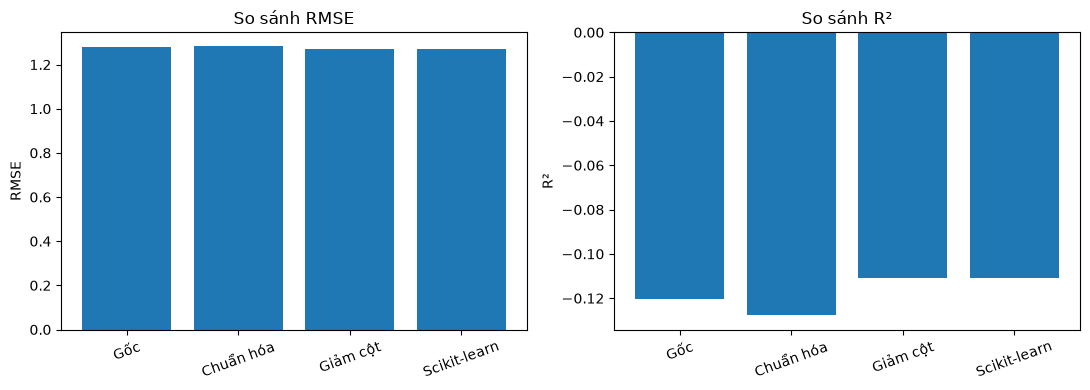

In [7]:
ten_mo_hinh = ['Gốc', 'Chuẩn hóa', 'Giảm cột', 'Scikit-learn']
cac_ket_qua = [ket_qua_goc, ket_qua_chuan, ket_qua_giam, ket_qua_thu_vien]
rmse = [x['RMSE'] for x in cac_ket_qua]
r2 = [x['R2'] for x in cac_ket_qua]

fig, truc = plt.subplots(1, 2, figsize=(11, 4))
truc[0].bar(ten_mo_hinh, rmse)
truc[0].set_title('So sánh RMSE')
truc[0].set_ylabel('RMSE')
truc[0].tick_params(axis='x', rotation=20)

truc[1].bar(ten_mo_hinh, r2)
truc[1].set_title('So sánh R²')
truc[1].set_ylabel('R²')
truc[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


## Nhận xét

- Chuẩn hóa thay đổi thang đo của đặc trưng nhưng gần như không thay đổi dự đoán của OLS.
- Loại hai cột tham chiếu làm ma trận không còn thiếu hạng mà vẫn giữ nguyên lượng thông tin.
- Mô hình NumPy và Scikit-learn cho kết quả gần như giống nhau vì đều giải bài toán OLS.
- Forest Fires là bài toán khó và biến `area` lệch mạnh, nên R² trên tập kiểm tra có thể thấp hoặc âm.
